# Case study: HCEA compartments

This tutorial reproduces the compartment analysis of the Human Cell
Epigenome Atlas (HCEA; Zhou, Wu, Liu *et al.*) with `epione`, from raw
single-cell contacts to cell-type compartment scores and the bins whose
compartment differs between cell types, in two parts:

**Part 1 — compartment calling**

1. Sum the raw contacts of the cells of each major type (`merge_cells`).
2. Fit one PCA model on the contacts of all cells merged: coverage filter,
   distance-normalised observed/expected (O/E), correlation, PCA; the PC with
   the stronger saddle contrast is the compartment axis, signed so that A is
   CpG-rich (`compartment_model`).
3. Project every major type on that model, so all types share one scale
   (`project_compartments`), and measure compartment strength with saddle
   plots (`compartment_saddle`).

**Part 2 — differential compartments**

4. Test every bin across major types with dcHiC's statistic. HCEA ran
   `dchicf.r --pcatype analyze` in R; `epi.bulk.hic.differential_compartments`
   is a Python port that gives the same numbers.
5. Select the differential bins and look at their patterns.

**Part 3 — single cells.** scHiCluster's single-cell compartment score
(`compartment_scores`), which needs no pseudobulk, and how it compares with
the cell-type scores.

Every step is checked against its reference (HCEA's published objects,
dcHiC in R, scHiCluster); the gates and measured errors are in
`tests/parity/schicluster_compartment/MANIFEST.md`.

**Data.** 13,166 HCEA nuclei profiled by snm3C-seq from the public release
(Hugging Face `zhoujt1994/HumanCellEpigenomeAtlas_sc_contact`): the six
haematopoietic major types — memory T cells (`c1`), myeloid cells (`c0`),
B cells (`c7`), naive T cells (`c15`), mast cells (`c24`) and NK cells
(`c27`) — from 15 tissues. Naive T, mast and NK cells are complete; the
other three are subsets of the atlas (memory T 4,344 of 7,914; myeloid 2,588
of 8,306; B 2,000 of 3,513). Each cell is a contact table
(`*.3C.contact.rmbkl.tsv.gz`, blacklist removed) with a median of about
200,000 long-range cis contacts. HCEA ran the same pipeline on all 86,689
cells and 35 major types; section 8 compares the two.

## 0 · Setup

In [1]:
import os
import pathlib
import warnings

import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')     # before importing epione: silences tqdm's IProgress notice
import matplotlib.pyplot as plt
import seaborn as sns
import cooler

import epione as epi
from epione.single import hic

epi.pl.plot_set()

# HCEA folder with sc_contact/, metadata/ and published/; override with EPIONE_HCEA_DIR.
DATA = pathlib.Path(os.environ.get('EPIONE_HCEA_DIR', 'data/hcea'))
FASTA = pathlib.Path(os.environ.get('EPIONE_HG38_FASTA', 'data/hg38/hg38.fa'))
OUT = pathlib.Path('result/t_sc_hic_compartment')
OUT.mkdir(parents=True, exist_ok=True)
NPROC = int(os.environ.get('EPIONE_NPROC', 16))

RES = 100_000
CHROMS = [f'chr{i}' for i in range(1, 23)]       # autosomes, as in HCEA
sizes = pd.read_csv(f'{FASTA}.fai', sep='\t', header=None, index_col=0)[1].loc[CHROMS]

files = sorted(DATA.glob('sc_contact/*/*.3C.contact.rmbkl.tsv.gz'))
print(f'{len(files):,} contact tables; FASTA present: {FASTA.exists()}')

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



13,166 contact tables; FASTA present: True


### Cell metadata

The HCEA summary table gives each cell's major type (`majortype`, HCEA's L1
code), tissue and donor; `L1color.tsv` maps codes to names and colours.

In [2]:
cell_ids = [f.name.split('.3C.')[0] for f in files]
meta = pd.read_csv(DATA / 'metadata/5kCG100k3C_summary.csv.gz', index_col=0).loc[cell_ids]
L1_meta = pd.read_csv(DATA / 'metadata/L1color.tsv', sep='\t', index_col=0)
TYPES = meta['majortype'].value_counts().index.tolist()          # L1 codes, largest first
L1_annot = L1_meta['L1_abbr'].to_dict()
L1_color = L1_meta['color'].to_dict()
# the atlas colours of the six blood types are close shades; use distinct hues here
L1_color.update({'c7': '#1f77b4', 'c24': '#ff7f0e', 'c0': '#2ca02c', 'c27': '#d62728',
                 'c1': '#9467bd', 'c15': '#17becf'})      # B, Mast, Myeloid, NK, Tmem, Tnaive
tab = pd.crosstab(meta['Tissue'], meta['majortype'].map(L1_annot), margins=True)
tab

majortype,Hema B,Hema Mast,Hema Myeloid,Hema NK,Hema Tmem,Hema Tnaive,All
Tissue,,,,,,,
AG,14,6,304,6,219,1,550
B,71,41,59,12,170,0,353
EG,138,235,399,45,519,0,1336
LG,25,164,359,191,495,2,1236
LV,4,53,256,39,84,0,436
M1C,0,0,0,6,0,3,9
NTb,3,36,261,4,92,0,396
P,0,0,0,12,0,7,19
PBMC,601,0,337,569,1400,1886,4793


## Part 1 · Compartment calling

### 1 · Raw contacts and pseudobulks

`contacts_to_scool` bins every cell at 100 kb exactly as scHiCluster's
`generate-scool` does (duplicates dropped, cis contacts closer than 2.5 kb
dropped, `(pos - 1) // 100 kb`), into one `.scool` that holds every raw
cell. `merge_cells` then sums the raw contacts of each major type into one
`.cool`, as `cooler merge` does, plus one cool
of all cells that defines the model. Compartments only use contacts within a
chromosome, so `cis_only=True` leaves out the trans pixels, which are most of
a genome-wide pseudobulk. Compartments are computed on **raw** contacts
throughout.

In [3]:
SCOOL = OUT / 'hcea_raw_100kb.scool'
if not SCOOL.exists():
    hic.contacts_to_scool(files, SCOOL, chrom_sizes=sizes, resolution=RES,
                          cell_ids=cell_ids, nproc=NPROC)
adata = hic.load_scool_cells(SCOOL, cell_names=cell_ids,
                             obs=meta[['majortype', 'Tissue', 'Donor', 'CisLongContact']])
adata.obs['merged'] = 'merged'

PB = OUT / 'pseudobulk'
cool_L1 = hic.merge_cells(adata, 'majortype', PB, cis_only=True, nproc=len(TYPES))
cool_merged = hic.merge_cells(adata, 'merged', PB, cis_only=True)['merged']
pd.DataFrame({'cells': adata.obs['majortype'].value_counts(),
              'contacts': {k: cooler.Cooler(v).info['sum'] for k, v in cool_L1.items()}}
             ).rename(index=L1_annot)

,cells,contacts
Hema Myeloid,2588,478381694
Hema Tmem,4344,776108456
Hema Tnaive,1915,336803333
Hema Mast,1246,254584280
Hema NK,1073,174611469
Hema B,2000,367958312


### 2 · CpG density

A compartments are CpG-rich, so CpG density fixes the sign of the PCs.
`cpg_ratio` counts `CG` over the non-`N` bases of each 100 kb bin (the same
numbers as `bedtools nuc -pattern CG -C`, which HCEA used).

In [4]:
CPG = OUT / 'cpg_ratio_100kb.tsv.gz'
if CPG.exists():
    cpg = pd.read_csv(CPG, sep='\t')
else:
    cpg = hic.cpg_ratio(FASTA, chrom_sizes=sizes, resolution=RES)
    cpg.to_csv(CPG, sep='\t', index=False)

### 3 · Fit the PC model with the merged raw contacts

`compartment_model` runs HCEA's fit per chromosome:

* **Bin filter.** With the diagonal removed, a bin is kept if its contacts
  exceed `2 × median − 99th percentile` of the non-empty bins (red lines
  below: median, 99th percentile and the threshold).
* **O/E.** Every pixel is divided by the mean of its diagonal.
* **Correlation and PCA.** Rows of `log2(O/E)` are correlated and the first
  two PCs computed. For each PC, bins are cut into 50 quantiles and the saddle
  contrast `(AA + BB) / (AB + BA)` of the outer 10 quantiles is computed; the
  PC with the higher contrast is kept and flipped to correlate positively
  with CpG density.

The returned table holds, per bin, the filter and the PC loading.

bins kept: 24,647 of 28,760
PC used per chromosome: {'PC1': 22}


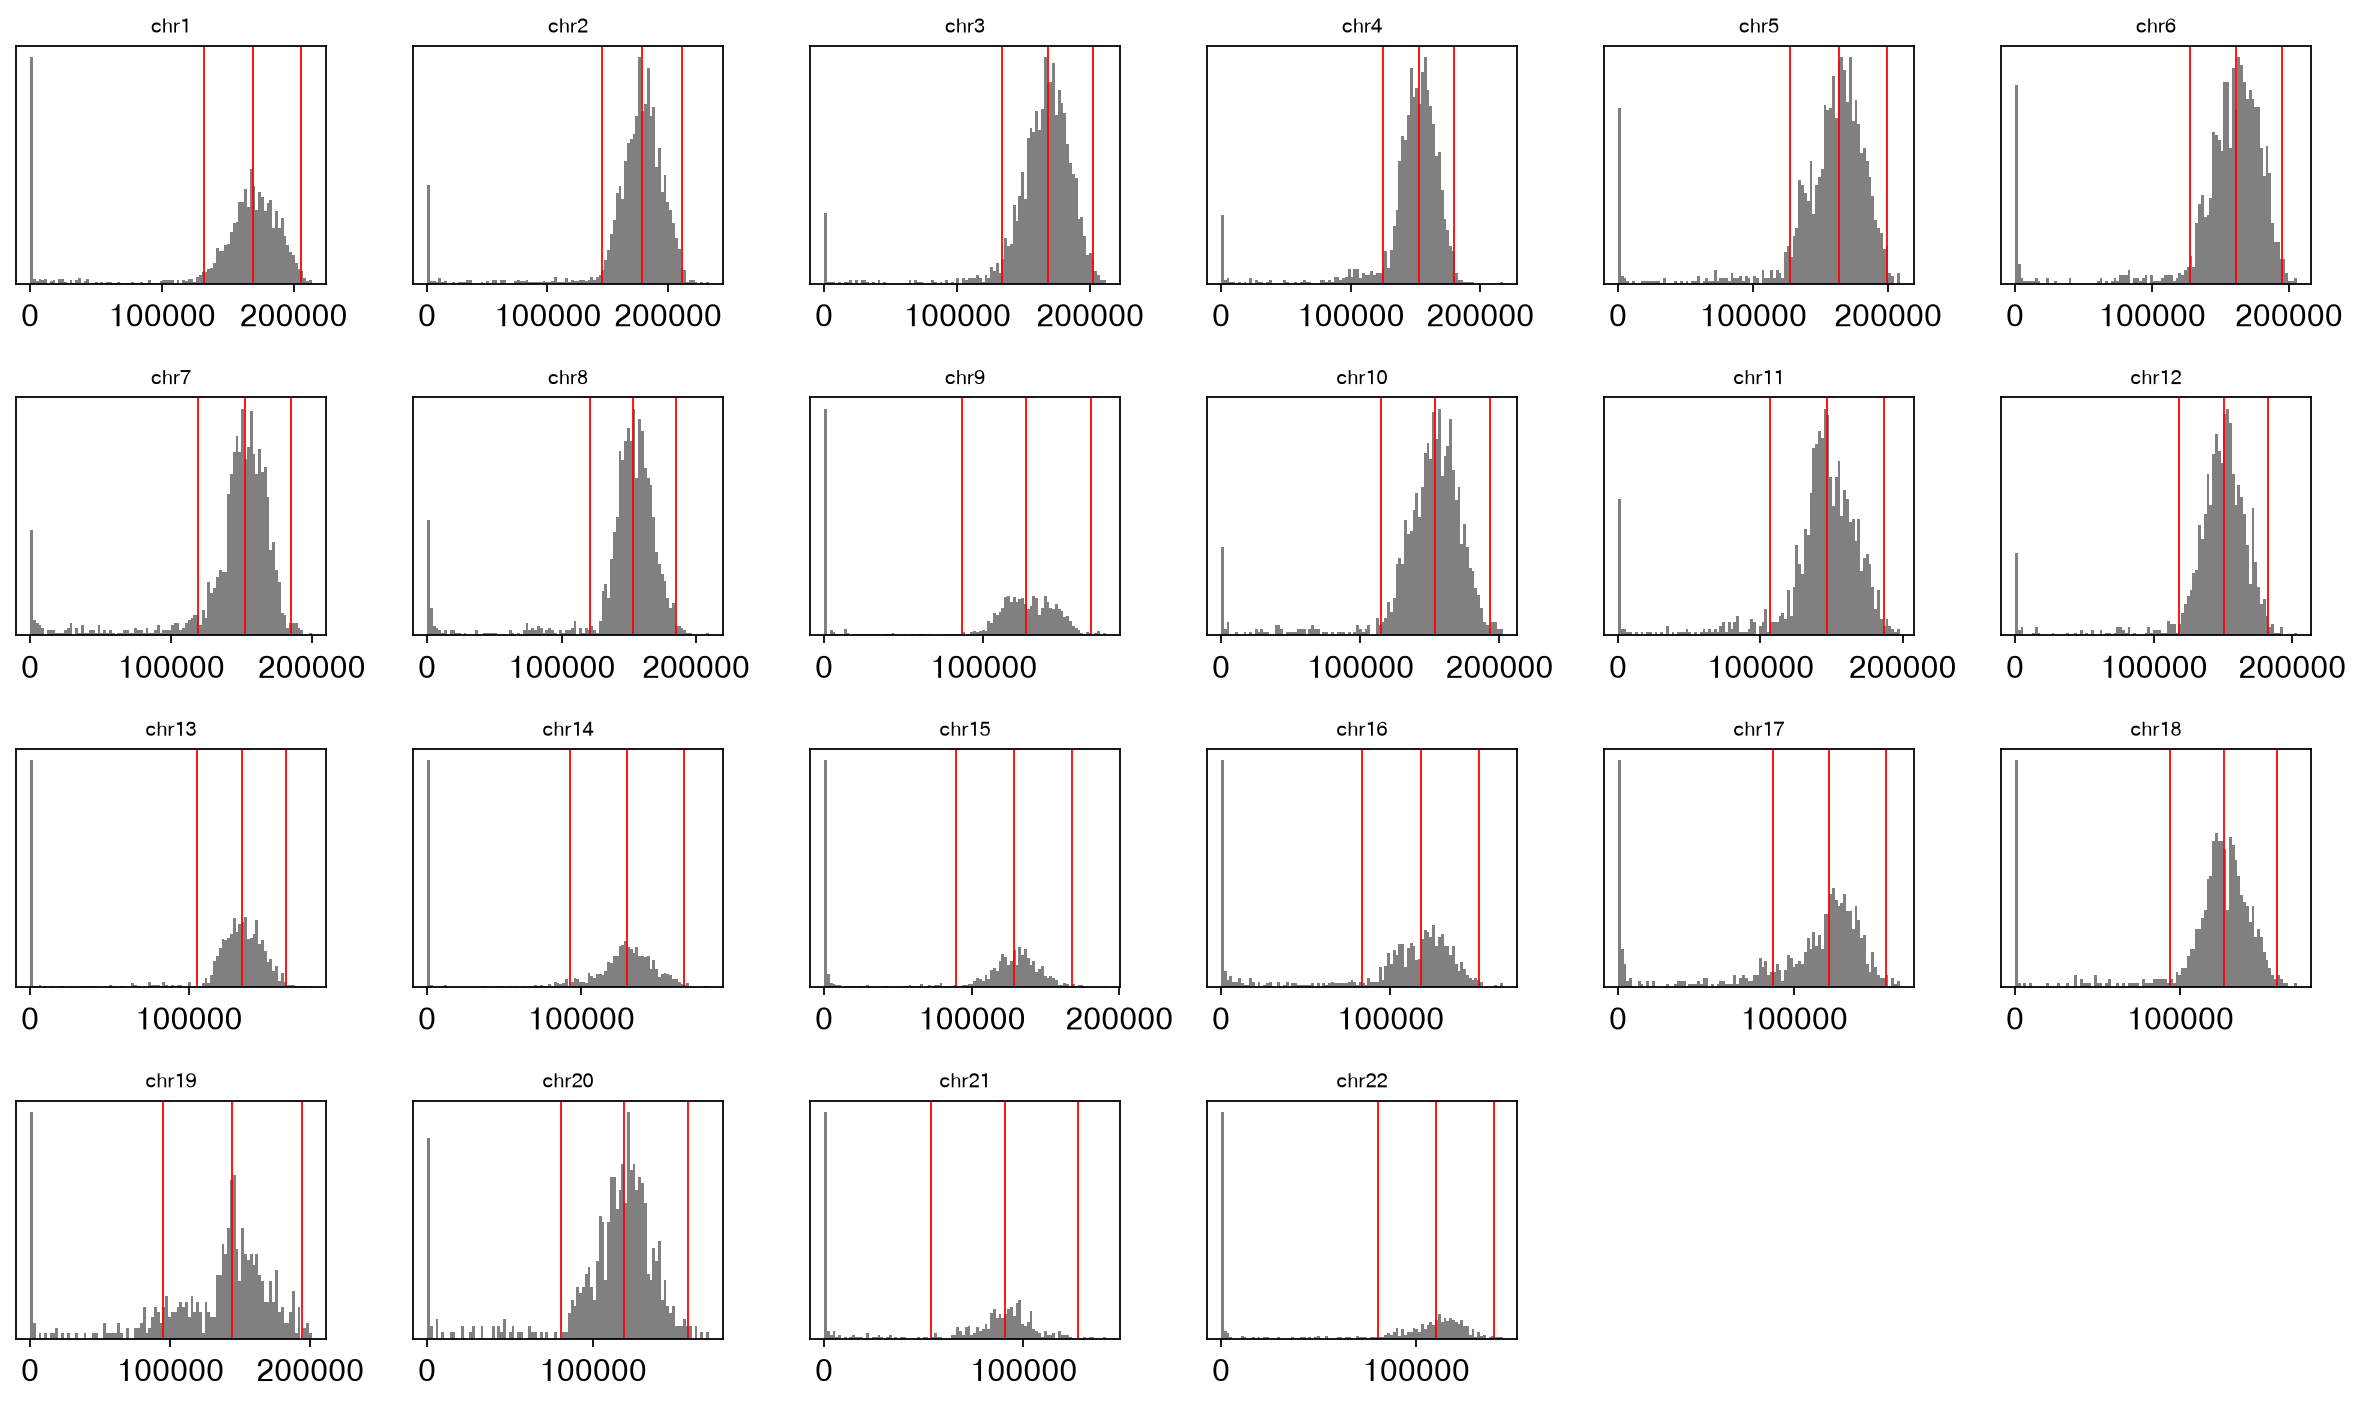

In [5]:
model = hic.compartment_model(cool_merged, cpg)
model.to_csv(OUT / 'merged_comp_model.tsv.gz', sep='\t', index=False)
print(f"bins kept: {model['keep'].sum():,} of {len(model):,}")
print('PC used per chromosome:', model.groupby('chrom', sort=False)['pc'].first().map({0: 'PC1', 1: 'PC2'}).value_counts().to_dict())

fig, axes = plt.subplots(4, 6, figsize=(15, 9))
for ax, c in zip(axes.flat, CHROMS):
    cov = model.loc[model['chrom'] == c, 'coverage'].to_numpy()
    nz = cov[cov > 0]
    p50, p99 = np.percentile(nz, [50, 99])
    ax.hist(cov, bins=100, color='0.5')
    for t in (p50, p99, 2 * p50 - p99):
        ax.axvline(t, color='r', lw=0.8)
    ax.set_title(c, fontsize=9); ax.set_yticks([])
for ax in axes.flat[len(CHROMS):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

Correlation matrices and the fitted compartment track of every chromosome.
The checkerboard is the A/B pattern; the track below each matrix is the
merged sample's score (red A, blue B; filtered bins are blank). Matrices are
shown in 300 kb blocks to keep the figure light.

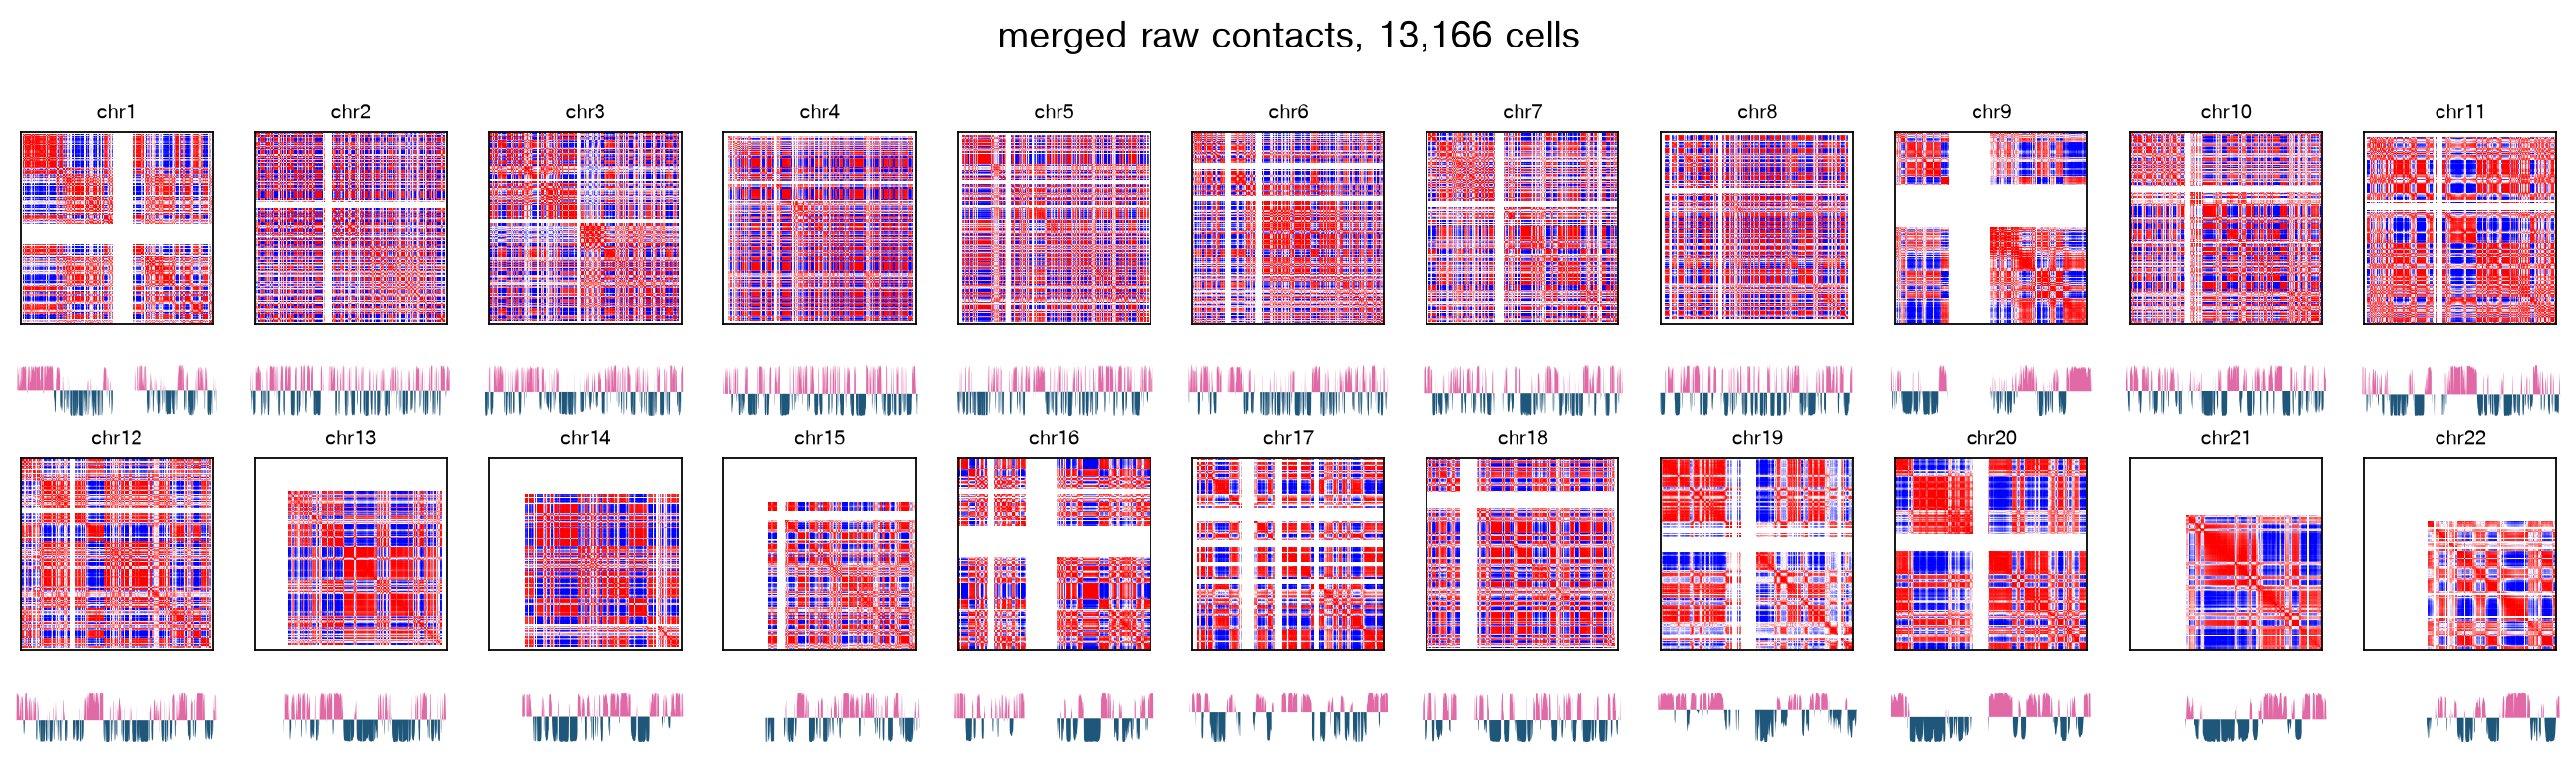

In [6]:
merged_score = hic.project_compartments({'merged': cool_merged}, model, clip=None)

def chrom_panels(cool, scores, column, title):
    fig, axes = plt.subplots(4, 11, figsize=(16.5, 4.8), height_ratios=[5, 1.3, 5, 1.3])
    for i, c in enumerate(CHROMS):
        r = (i // 11) * 2
        m = model[model['chrom'] == c]
        _, C = hic.oe_correlation(cool, c, keep=m['keep'].to_numpy())
        n = len(m)
        full = np.full((n, n), np.nan)
        k = np.where(m['keep'])[0]
        full[np.ix_(k, k)] = C
        f = 3                                   # show 300 kb blocks (display only)
        nb_ = n // f
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', RuntimeWarning)
            disp = np.nanmean(full[:nb_ * f, :nb_ * f].reshape(nb_, f, nb_, f), axis=(1, 3))
        ax = axes[r, i % 11]
        ax.imshow(disp, cmap='bwr', vmin=np.percentile(C, 5), vmax=np.percentile(C, 95),
                  interpolation='none', rasterized=True)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(c, fontsize=9)
        ax = axes[r + 1, i % 11]
        y = np.zeros(n)
        y[k] = scores.loc[scores['chrom'] == c, column].to_numpy()
        x = np.arange(n)
        ax.fill_between(x, y, 0, where=y >= 0, color='C3', lw=0)
        ax.fill_between(x, y, 0, where=y <= 0, color='C0', lw=0)
        ax.set_xlim(0, n); ax.set_ylim(np.percentile(y, 1), np.percentile(y, 99))
        ax.axis('off')
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()

chrom_panels(cool_merged, merged_score, 'merged', f'merged raw contacts, {len(cell_ids):,} cells')

PC1 is the compartment axis on every chromosome, and 24,647 of the 28,760
autosomal bins pass the filter (24,478 in the full atlas). The filtered bins
are centromeres, gaps and the short arms of the acrocentric chromosomes
(chr13–15, 21, 22).

### 4 · Project every major type on the merged model

For each major type, `project_compartments` builds the correlation matrix on
the model's bins (O/E as above, clipped at the 5th / 95th percentiles, as in
HCEA) and projects it on the merged loadings. All types share
one axis, so a bin that is A in one type and B in another changes sign. The
scores are written as one bedGraph per type, as HCEA did.

HCEA fitted its published model on the unclipped correlation matrix and
clipped only when projecting; these are the function defaults, and with them
epione reproduces the published loadings (max error 1.2e-15) and the scores of
all 35 published major types (max error 5.3e-14).

In [7]:
comp = hic.project_compartments(cool_L1, model, nproc=len(TYPES))
for ct in TYPES:
    hic.write_bedgraph(comp, ct, OUT / f'{ct}.raw.bedgraph')
comp.to_csv(OUT / 'comp.raw.tsv.gz', sep='\t', index=False)
comp[TYPES].rename(columns=L1_annot).corr().round(3)

,Hema Tmem,Hema Myeloid,Hema B,Hema Tnaive,Hema Mast,Hema NK
Hema Tmem,1.000,0.837,0.919,0.963,0.842,0.949
Hema Myeloid,0.837,1.000,0.876,0.853,0.853,0.877
Hema B,0.919,0.876,1.000,0.923,0.858,0.928
Hema Tnaive,0.963,0.853,0.923,1.000,0.855,0.952
Hema Mast,0.842,0.853,0.858,0.855,1.000,0.870
Hema NK,0.949,0.877,0.928,0.952,0.870,1.000


The six types share most of their compartments (r = 0.84–0.96 between
their tracks). The lymphocytes are the most alike (naive and memory T cells
0.96, NK cells with either T type 0.95); myeloid and mast cells are the most
distinct (0.84–0.88 with every other type).

All types on one chromosome: correlation matrix and projected score of chr5,
which carries the strongest difference between the types (Part 2).

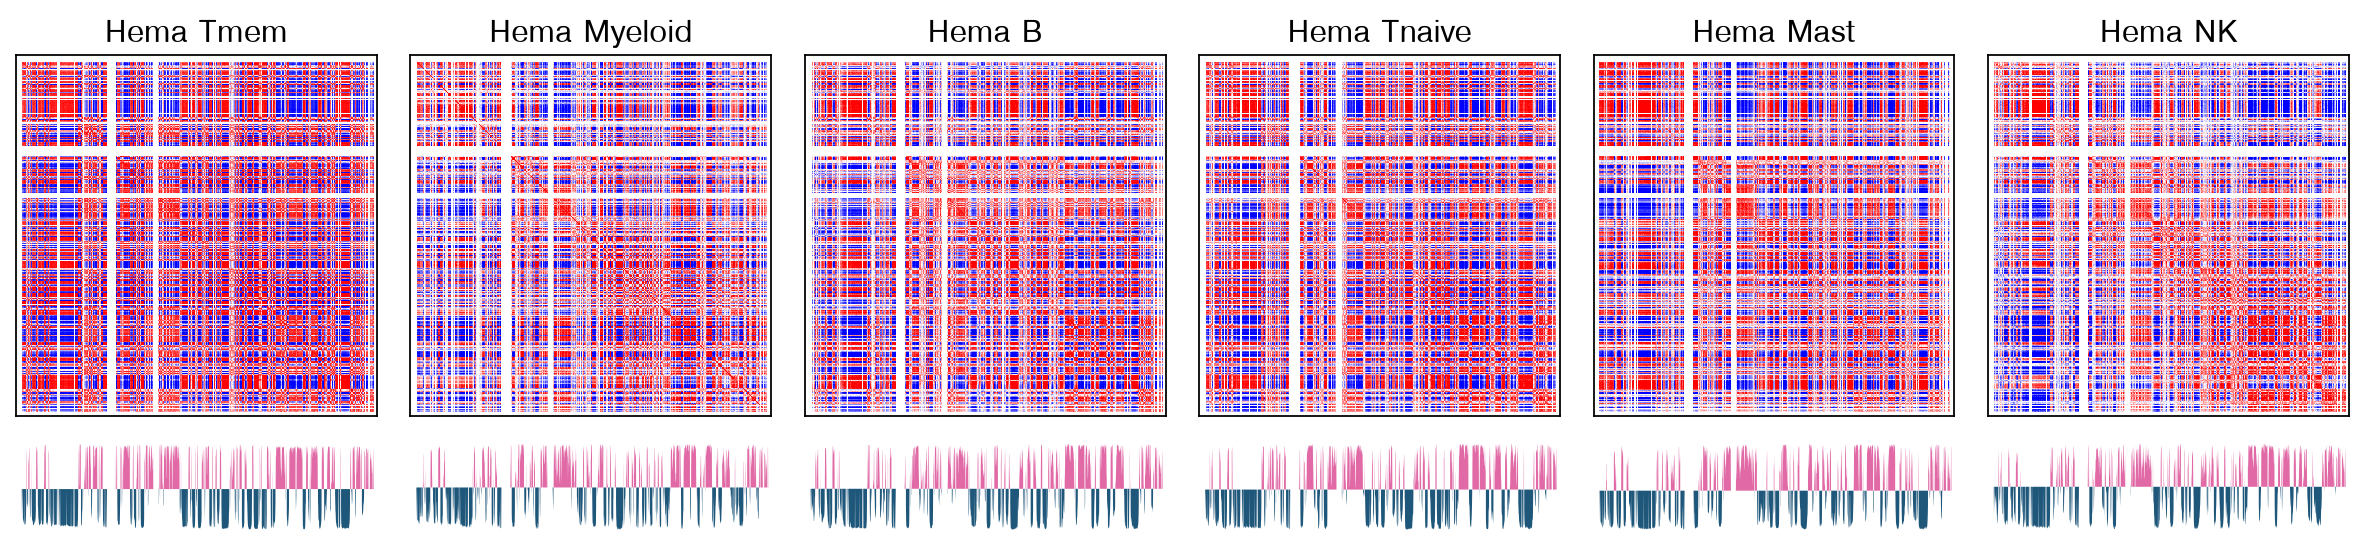

In [8]:
C15 = 'chr5'
m15 = model[model['chrom'] == C15]
k15 = np.where(m15['keep'])[0]
fig, axes = plt.subplots(2, len(TYPES), figsize=(2.5 * len(TYPES), 3.6), height_ratios=[5, 1.2],
                         sharex='col')
for j, ct in enumerate(TYPES):
    _, C = hic.oe_correlation(cool_L1[ct], C15, keep=m15['keep'].to_numpy())
    full = np.full((len(m15), len(m15)), np.nan)
    full[np.ix_(k15, k15)] = C
    axes[0, j].imshow(full, cmap='bwr', vmin=np.percentile(C, 5), vmax=np.percentile(C, 95),
                      interpolation='none', rasterized=True)
    axes[0, j].set_title(L1_annot[ct]); axes[0, j].set_xticks([]); axes[0, j].set_yticks([])
    y = np.zeros(len(m15)); y[k15] = comp.loc[comp['chrom'] == C15, ct].to_numpy()
    x = np.arange(len(m15))
    axes[1, j].fill_between(x, y, 0, where=y >= 0, color='C3', lw=0)
    axes[1, j].fill_between(x, y, 0, where=y <= 0, color='C0', lw=0)
    axes[1, j].set_xlim(0, len(m15)); axes[1, j].axis('off')
plt.tight_layout(); plt.show()

### 5 · Saddle plots and compartment strength

`compartment_saddle` cuts each chromosome's bins into 50 quantiles of the
projected score (B → A), averages O/E over every pair of quantiles and sums
over chromosomes. The corners of the outer 10 quantiles give `BB`, `AA`, `BA`,
`AB`, and `strength = (AA + BB) / (AB + BA)`. The numbers in the corners are
the AA/AB and BB/BA ratios, as in HCEA's figure.

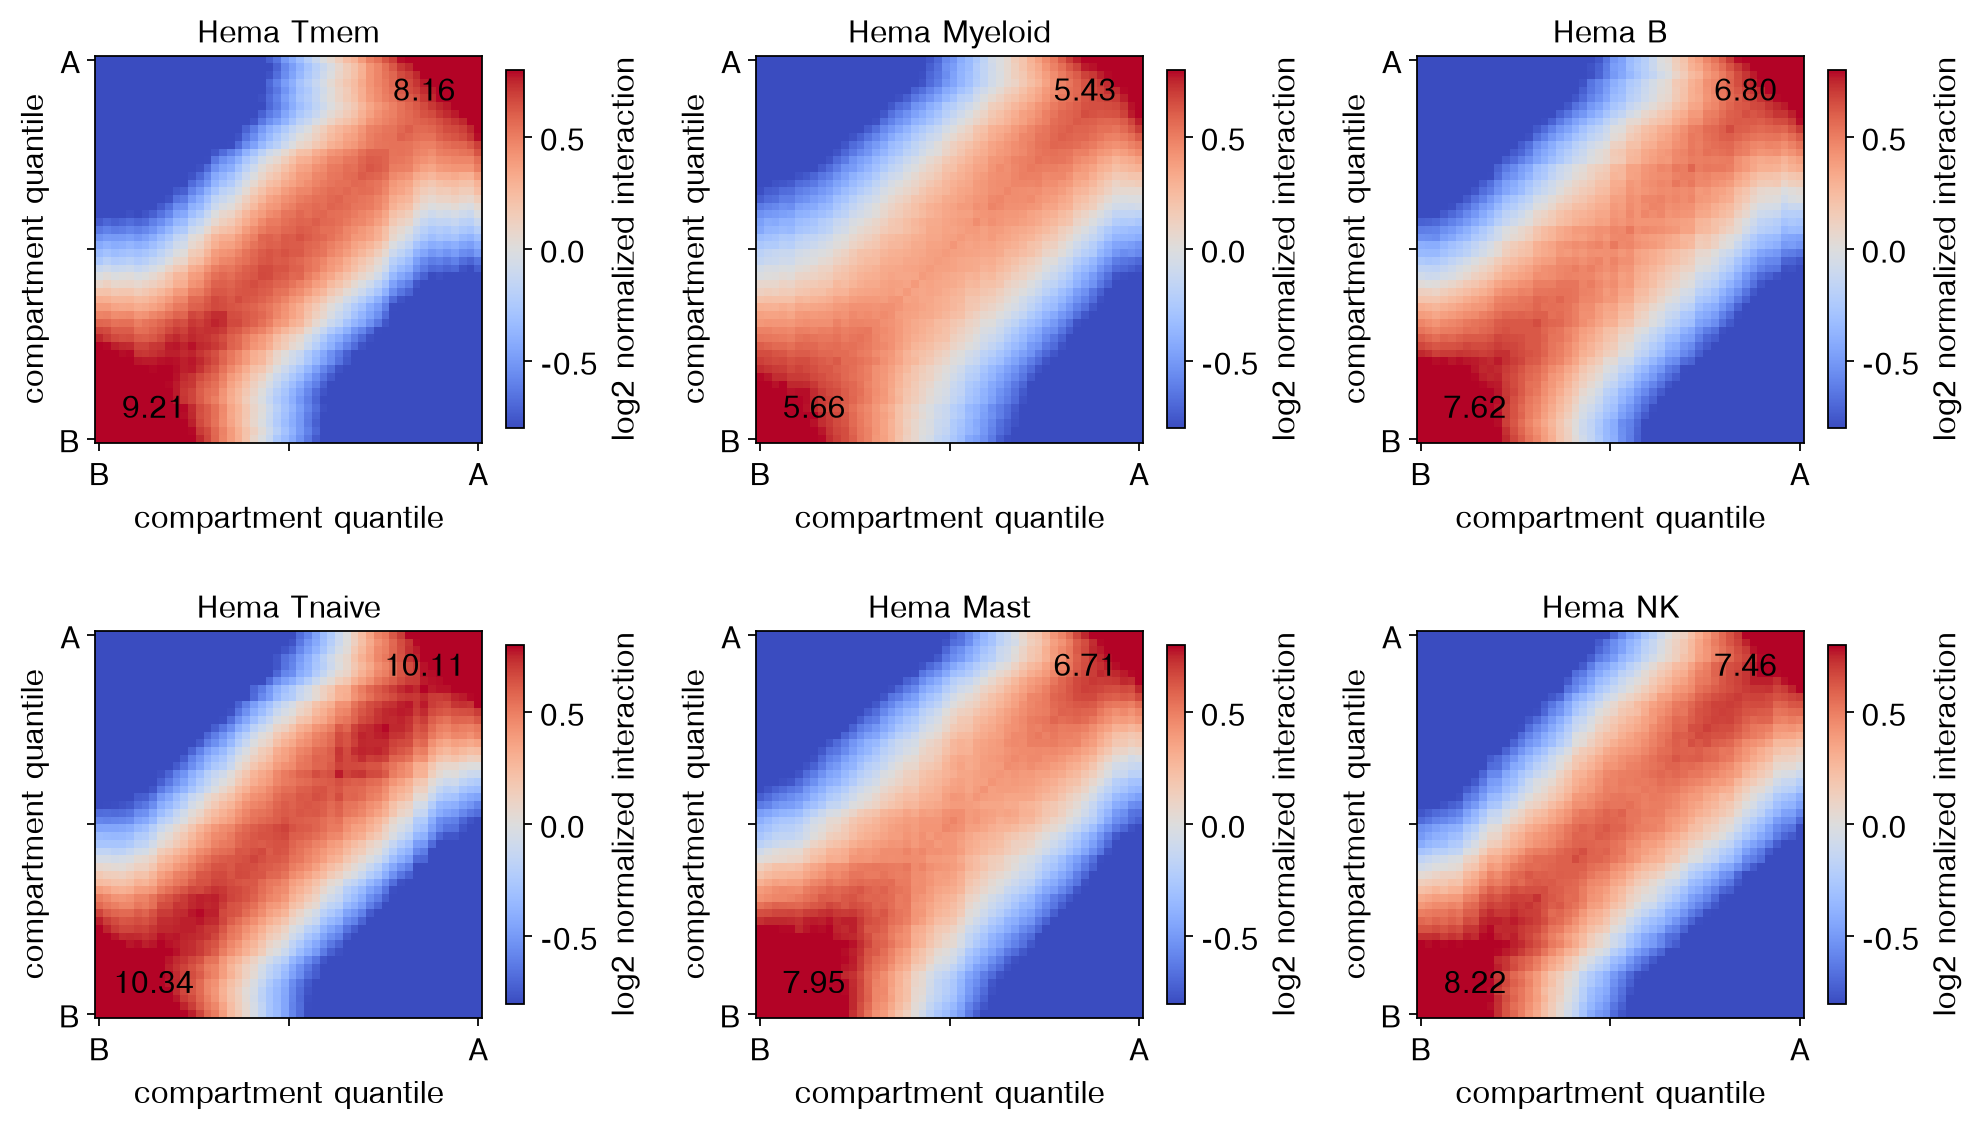

,BB,AA,BA,AB,strength
Hema Myeloid,1.742,1.672,0.308,0.308,5.548
Hema B,1.933,1.726,0.254,0.254,7.211
Hema Mast,1.993,1.682,0.251,0.251,7.328
Hema NK,1.907,1.729,0.232,0.232,7.840
Hema Tmem,2.016,1.787,0.219,0.219,8.686
Hema Tnaive,1.922,1.879,0.186,0.186,10.226


In [9]:
sad = {ct: hic.compartment_saddle(cool_L1[ct], model) for ct in TYPES}
compstr = pd.DataFrame({ct: s['strength'] for ct, s in sad.items()}).T
compstr.index = compstr.index.map(L1_annot)

fig, axes = plt.subplots(2, 3, figsize=(12.6, 7.4))
for ax, ct in zip(axes.flat, TYPES):
    s = sad[ct]['strength']
    epi.pl.plot_saddle(sad[ct]['saddle'], ax=ax, vmin=-0.8, vmax=0.8, title=L1_annot[ct],
                       label='log2 normalized interaction')
    ax.text(42, 45, f"{s['AA'] / s['AB']:.2f}", ha='center', va='center')
    ax.text(7, 4, f"{s['BB'] / s['BA']:.2f}", ha='center', va='center')
plt.tight_layout(); plt.show()
compstr.sort_values('strength').round(3)

Naive T cells are the most compartmentalised (strength 10.2), then memory T
(8.7), NK (7.8), mast (7.3) and B cells (7.2); myeloid cells are the least
(5.5). Myeloid cells also have the most short-range contacts (decay tutorial);
across the other types, strength and the short/long ratio do not follow the
same order.

## Part 2 · Differential compartments

### 6 · dcHiC across major types

HCEA wrote each type's scores as dcHiC's per-chromosome `pc.bedGraph` files
(sample `<type>_100Kb`, condition `<type>`) and ran
`Rscript dchicf.r --pcatype analyze`. dcHiC

* quantile-normalises the scores of all samples per chromosome
  (`limma::normalizeQuantiles`) and scales each by its mean absolute value;
* for every bin, takes the Mahalanobis distance between the condition means
  and a shrunk centre, using a robust covariance estimated across bins
  (`robust::covRob`), scaled by the squared range of the condition means
  (`sample_maha`);
* re-estimates the covariance without the outlying bins (`refine`), turns
  the distance into a χ² p-value with (conditions − 1) degrees of freedom and
  adjusts it with Benjamini–Hochberg (IHW when there are replicates).

`epi.bulk.hic.differential_compartments` does the same on the score table in
memory. Here dcHiC gets the raw-contact scores of section 4. HCEA's published
differential compartments used scores of *imputed* contacts projected on the
same raw model and bins, so its numbers differ from these; the dcHiC statistic
itself is the same. `covRob` chooses its estimator from the number of types
and of bins per chromosome: with these six types it uses MCD on chromosomes
with at least 1,000 bins (chr1–12) and Donoho–Stahel on the others; with
HCEA's 35 types it uses OGK. All three are ported from R, including R's random
number stream that MCD and Donoho–Stahel draw from, and match it (see the
MANIFEST). `out_dir=` also writes dcHiC's result tree, and
`epi.bulk.hic.dchic_analyze` runs from dcHiC's own `input.txt` layout.

In [10]:
scores = comp.rename(columns={ct: f'{ct}_100Kb' for ct in TYPES})
res = epi.bulk.hic.differential_compartments(
    scores, {f'{ct}_100Kb': ct for ct in TYPES}, out_dir=OUT / 'DifferentialResult')
res.index = res['chr'] + '_' + (res['start'] // RES).astype(str)
binall = res[['chr', 'start', 'end', 'sample_maha', 'pval', 'padj']].copy()
dcomp = res[TYPES]                      # quantile-normalised score, mean per type
print(f'{len(res):,} bins tested; padj < 0.1: {(res.padj < 0.1).sum():,}')
binall.sort_values('sample_maha', ascending=False).head()

24,647 bins tested; padj < 0.1: 9,282


,chr,start,end,sample_maha,pval,padj
chr5_893,chr5,89300000,89400000,13683.387265,0.0,0.0
chr5_892,chr5,89200000,89300000,13617.403095,0.0,0.0
chr5_894,chr5,89400000,89500000,11863.739641,0.0,0.0
chr4_855,chr4,85500000,85600000,10645.231065,0.0,0.0
chr4_857,chr4,85700000,85800000,10450.618620,0.0,0.0


9,282 of 24,647 bins (38 %) have padj < 0.1. With six well-separated cell
types and 100 kb bins, a large part of the genome passes a nominal FDR, which
is why HCEA ranked bins by the size of the statistic instead (next section).

### 7 · Select differential bins

With many bins and well-separated types, most bins pass a nominal FDR, so HCEA
selected bins on the size of the statistic instead: z-score of `sample_maha`
across bins above the upper 10 % normal quantile.

differential bins: 1,278 of 24,647


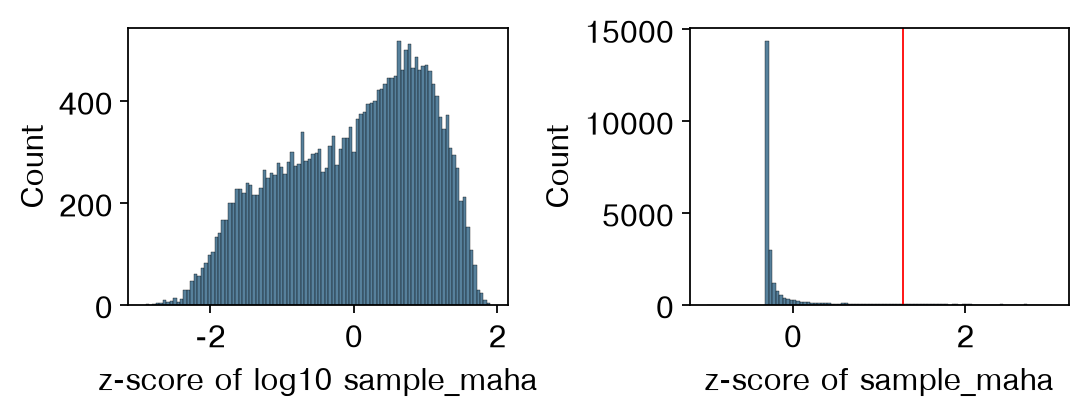

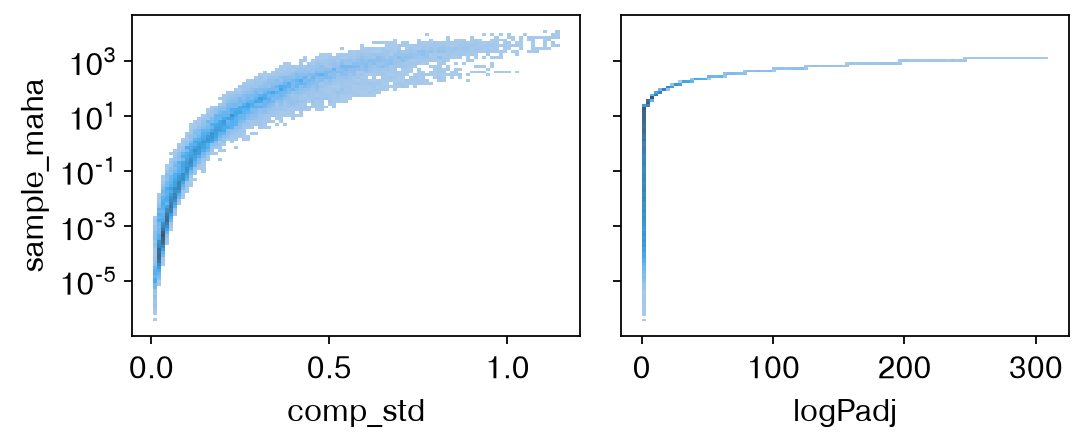

In [11]:
from scipy.stats import zscore, norm

binall['logPadj'] = -np.log10(binall['padj']).clip(upper=300)
binall['comp_std'] = dcomp.std(axis=1, ddof=0)
z = pd.Series(zscore(binall['sample_maha']), index=binall.index)
selb = z > norm.isf(0.1)
print(f'differential bins: {selb.sum():,} of {len(binall):,}')

fig, axes = plt.subplots(1, 2, figsize=(7, 2.8))
sns.histplot(zscore(np.log10(binall['sample_maha'])), bins=100, ax=axes[0])
axes[0].set_xlabel('z-score of log10 sample_maha')
sns.histplot(z, bins=100, binrange=(-1, 3), ax=axes[1])
axes[1].axvline(norm.isf(0.1), color='r', lw=0.8)
axes[1].set_xlabel('z-score of sample_maha')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(7, 3), sharey=True)
sns.histplot(binall, x='comp_std', y='sample_maha', bins=100, ax=axes[0], log_scale=(False, 10))
sns.histplot(binall, x='logPadj', y='sample_maha', bins=100, ax=axes[1], log_scale=(False, 10))
plt.tight_layout(); plt.show()

The differential bins, clustered by cosine distance of their normalised
scores (HCEA's heatmap): each block is a set of bins that are A in some types
and B in others.

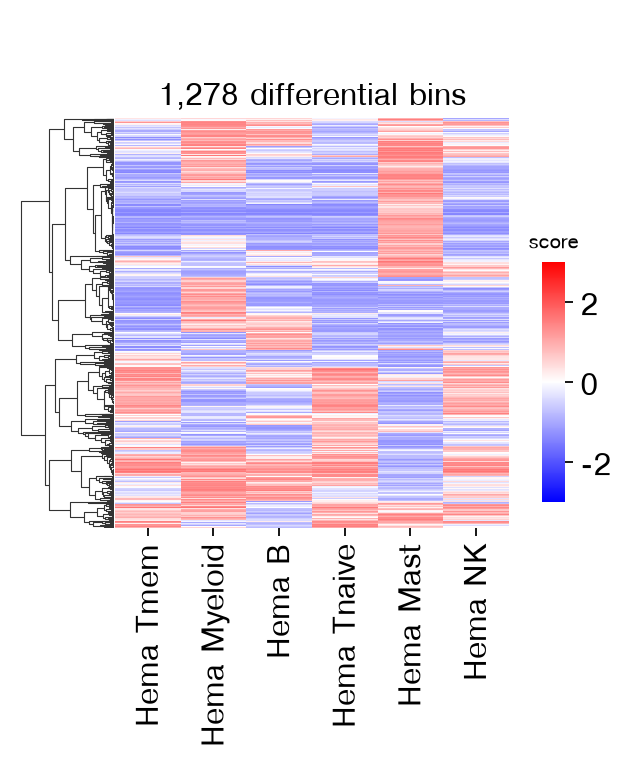

bins
Hema Tmem Hema Myeloid Hema B Hema Tnaive Hema Mast Hema NK      
B         B            B      B           A         B         181
          A            B      B           A         B         110
                                          B         B          87
A         B            B      A           B         A          81
          A            A      A           B         A          77
B         A            A      B           B         B          61
A         A            B      A           A         A          53
          B            A      A           B         A          47
B         A            A      B           A         B          40
          B            A      B           B         B          38

In [12]:
tmp3c = dcomp.loc[selb].to_numpy()
cg = sns.clustermap(tmp3c, cmap='bwr', vmin=-3, vmax=3, metric='cosine', col_cluster=False,
                    figsize=(3.5, 5), xticklabels=[L1_annot[c] for c in TYPES],
                    yticklabels=[], cbar_pos=(1.0, 0.35, 0.04, 0.3))
cg.ax_cbar.set_title('score', fontsize=9)
cg.ax_heatmap.set_ylabel('')
cg.ax_heatmap.set_title(f'{tmp3c.shape[0]:,} differential bins')
plt.show()

pattern = pd.DataFrame(np.sign(tmp3c), columns=[L1_annot[c] for c in TYPES]).replace({1: 'A', -1: 'B'})
pattern.value_counts().rename('bins').to_frame().head(10)

1,278 bins pass the selection. The largest groups are A only in mast cells
(181 bins), A in myeloid and mast cells (110), A only in myeloid cells (87),
and A in the T and NK cells but B in the others (81).

A differential region in the browser: the projected tracks of all types and
the statistic around the strongest differential bin.

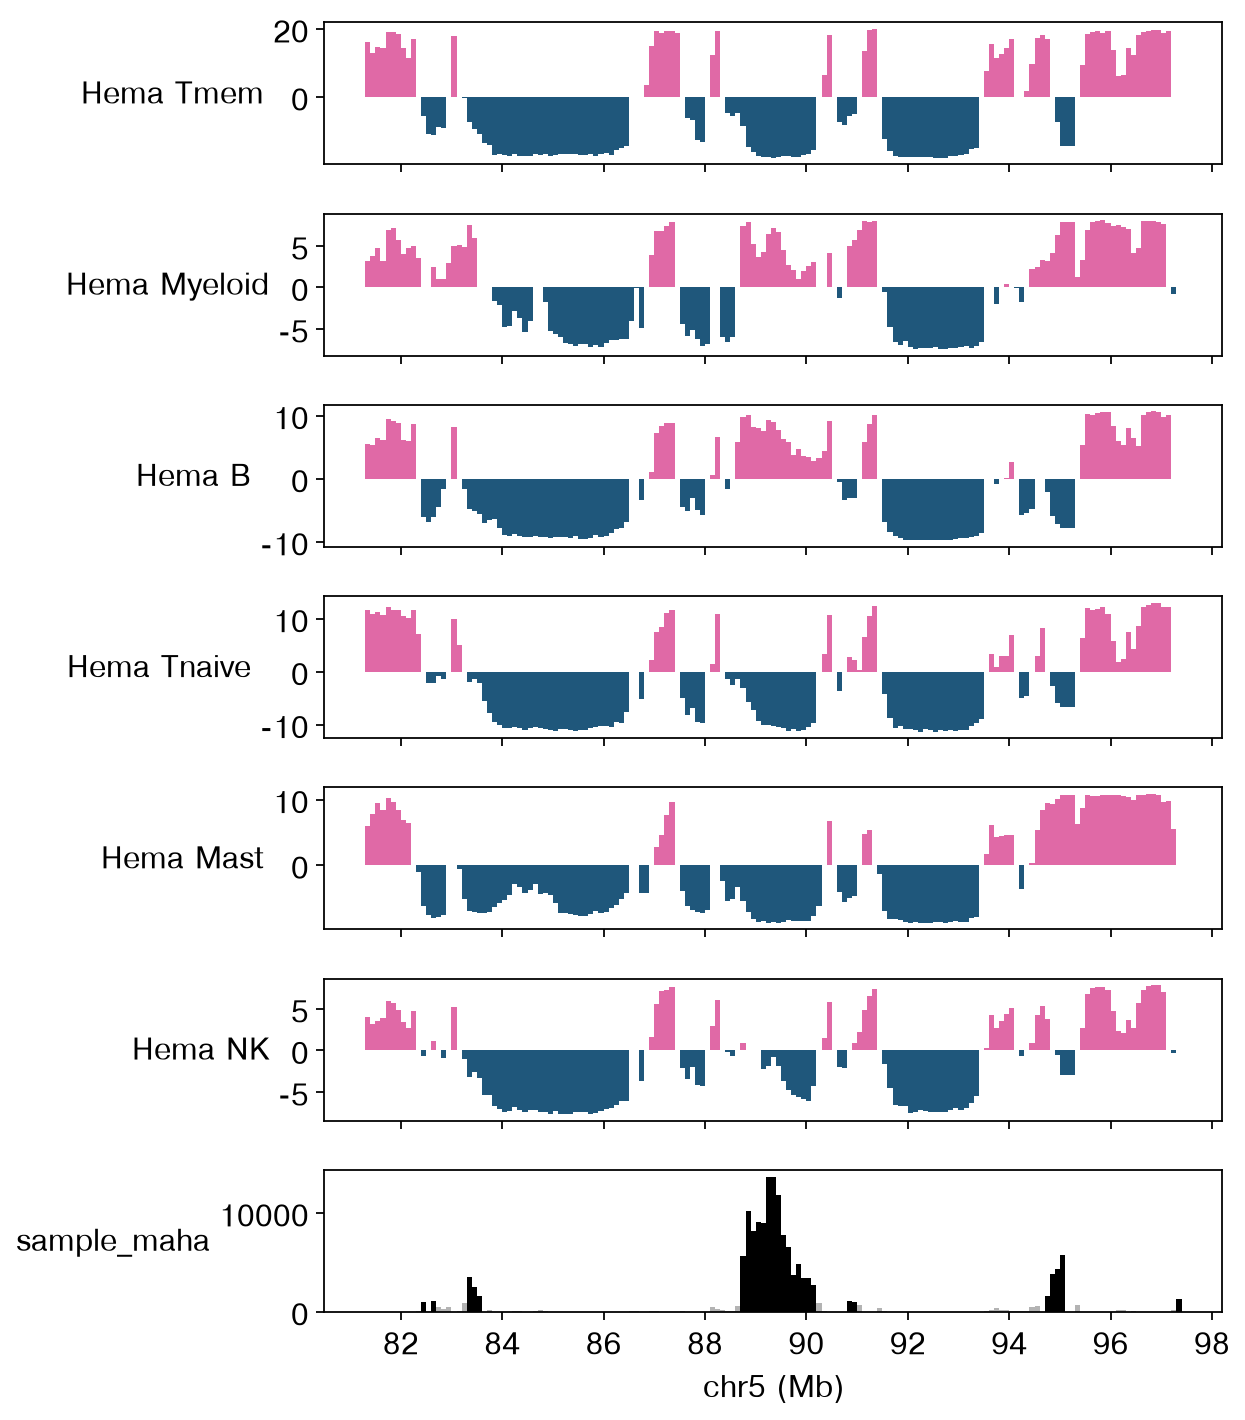

In [13]:
top = binall.loc[selb].sort_values('sample_maha', ascending=False).iloc[0]
c, mid = top['chr'], top['start']
win = comp[(comp['chrom'] == c) & (comp['start'].between(mid - 8e6, mid + 8e6))]
w2 = binall[(binall['chr'] == c) & (binall['start'].between(mid - 8e6, mid + 8e6))]
fig, axes = plt.subplots(len(TYPES) + 1, 1, figsize=(8, 1.3 * (len(TYPES) + 1)), sharex=True)
for ax, ct in zip(axes, TYPES):
    x, y = win['start'] / 1e6, win[ct]
    ax.fill_between(x, y, 0, where=y >= 0, color='C3', lw=0, step='post')
    ax.fill_between(x, y, 0, where=y <= 0, color='C0', lw=0, step='post')
    ax.set_ylabel(L1_annot[ct], rotation=0, ha='right', va='center')
axes[-1].bar(w2['start'] / 1e6, w2['sample_maha'], width=0.1, align='edge',
             color=np.where(selb.loc[w2.index], 'k', '0.7'))
axes[-1].set_ylabel('sample_maha', rotation=0, ha='right', va='center')
axes[-1].set_xlabel(f'{c} (Mb)')
plt.tight_layout(); plt.show()

The strongest differential region, chr5 ≈ 88.8–90.2 Mb, is A in myeloid and
B cells and B in memory T, naive T and mast cells, with NK cells weakly B; the
flanking blocks keep the same compartment in every type.

### 8 · Validation against the published atlas

HCEA's published scores for these six major types come from all 86,689
cells and are on the atlas-wide model. If
`published/hcea_L1_compartment_raw_hema.tsv.gz` is present, we compare bin by
bin.

24,377 shared bins


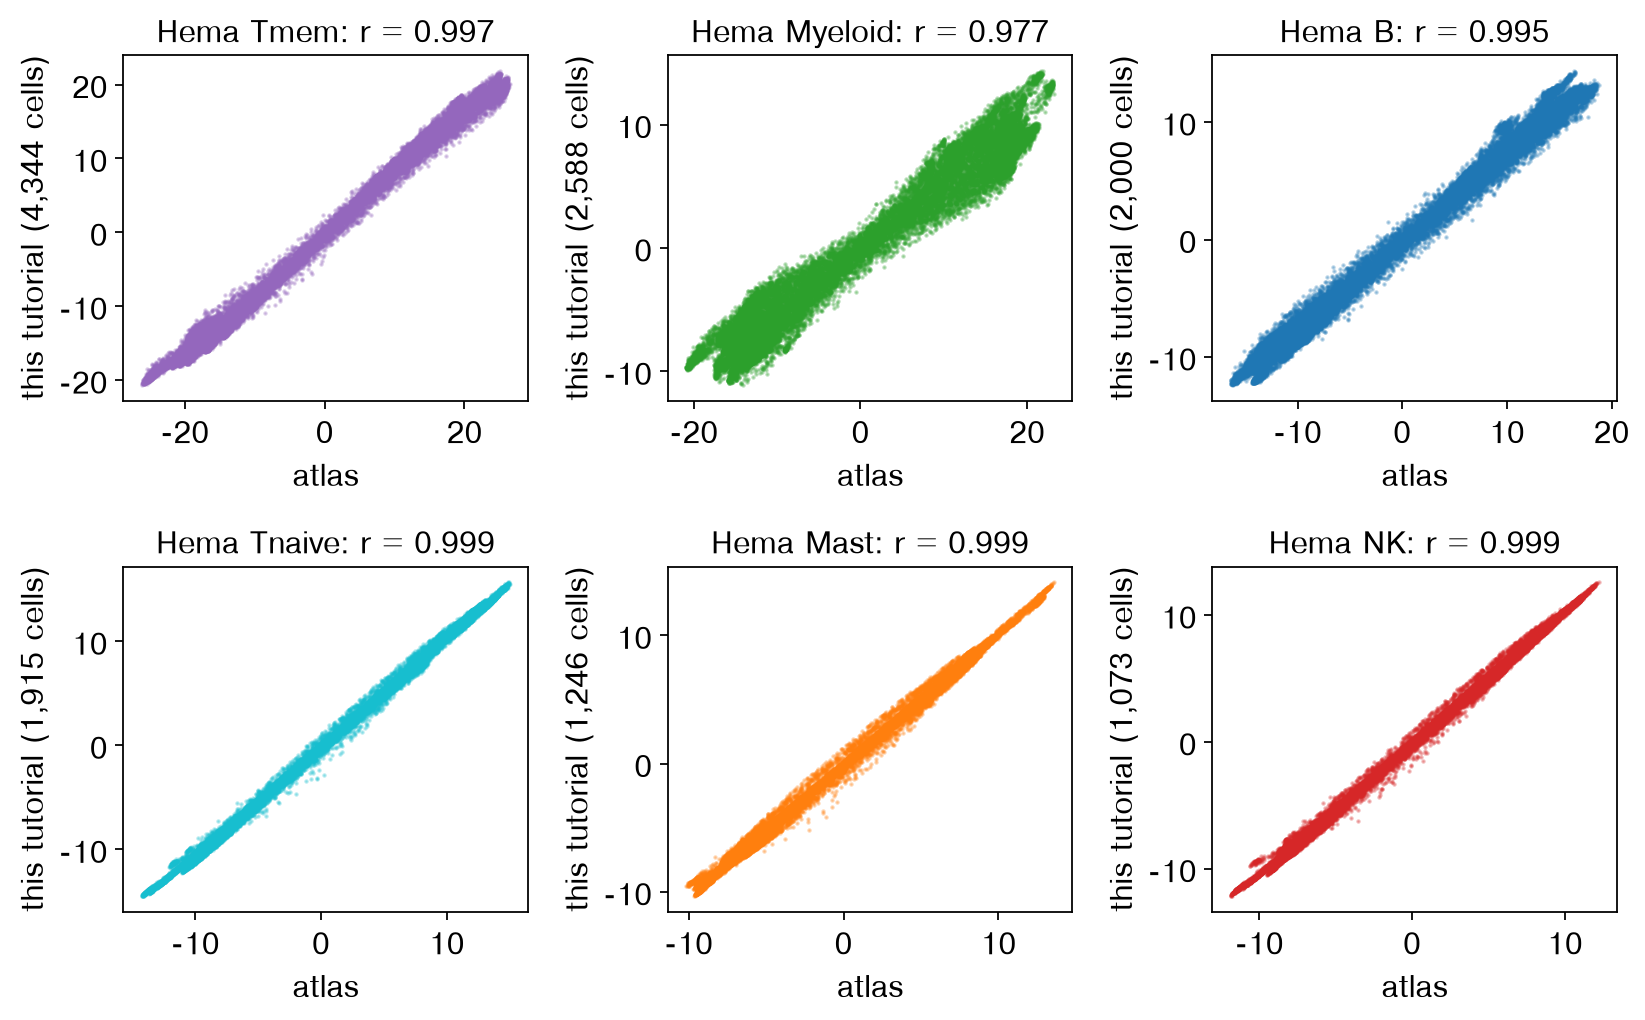

In [14]:
PUB = DATA / 'published/hcea_L1_compartment_raw_hema.tsv.gz'
if PUB.exists():
    pub = pd.read_csv(PUB, sep='\t')
    both = comp.merge(pub, on=['chrom', 'start', 'end'], suffixes=('', '_atlas'))
    print(f'{len(both):,} shared bins')
    n_type = adata.obs['majortype'].value_counts()
    fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.6))
    for ax, ct in zip(axes.flat, TYPES):
        x, y = both[f'{ct}_atlas'], both[ct]
        ax.scatter(x, y, s=1, alpha=0.3, color=L1_color[ct], rasterized=True)
        ax.set_xlabel('atlas'); ax.set_ylabel(f'this tutorial ({n_type[ct]:,} cells)')
        ax.set_title(f'{L1_annot[ct]}: r = {np.corrcoef(x, y)[0, 1]:.3f}')
    plt.tight_layout(); plt.show()
else:
    print('published table not found; skipping')

The types that are complete here (naive T, mast and NK cells) reproduce the
atlas almost exactly (r = 0.999); the remaining differences come from the
merged model, fitted on 13,166 instead of 86,689 cells. The subsampled types
agree closely too (memory T 0.997, B 0.995, myeloid 0.977).

## Part 3 · Single-cell compartment scores (scHiCluster)

Pseudobulks need many cells. scHiCluster's score is defined for one cell:
for each chromosome, `compartment_scores` removes the diagonal, normalises
each row of the raw contact matrix to sum to one and multiplies by the CpG
vector, so a bin's score is the CpG density of the bins it contacts.
`calc_strength=True` adds per-cell AA / BB / AB sums of distance-normalised
contacts between the top-20 % and bottom-20 % bins.

In [15]:
SC = OUT / 'sc_compartment.h5ad'
if SC.exists():
    import anndata as ad
    sc_comp = ad.read_h5ad(SC)
    sc_comp.obs['majortype'] = adata.obs.loc[sc_comp.obs_names, 'majortype'].to_numpy()
else:
    sc_comp = hic.compartment_scores(adata, cpg, calc_strength=True, nproc=NPROC, progress=False)
    sc_comp.write_h5ad(SC)
sc_comp

AnnData object with n_obs × n_vars = 13166 × 28760
    obs: 'cool_path', 'major_type', 'Tissue', 'Donor', 'CisLongContact', 'majortype'
    var: 'chrom', 'start', 'end', 'cpg_ratio'
    uns: 'compartment', 'compartment_strength_per_chrom', 'hic'
    obsm: 'compartment_strength'

Averaged over the cells of a type, the single-cell score tracks the projected
cell-type score of section 4, although the two methods share nothing but the
contacts.

In [16]:
from scipy.stats import spearmanr
key = (comp['chrom'] + ':' + comp['start'].astype(str)).to_numpy()
col = pd.Series(np.arange(sc_comp.n_vars),
                index=(sc_comp.var['chrom'].astype(str) + ':' + sc_comp.var['start'].astype(str)).to_numpy()).loc[key].to_numpy()
pd.Series({L1_annot[ct]: spearmanr(np.asarray(sc_comp.X[(sc_comp.obs['majortype'] == ct).to_numpy()][:, col]).mean(0),
                                   comp[ct]).correlation for ct in TYPES},
          name='Spearman, mean single-cell score vs projected score').round(3)

Hema Tmem       0.679
Hema Myeloid    0.633
Hema B          0.697
Hema Tnaive     0.713
Hema Mast       0.669
Hema NK         0.723
Name: Spearman, mean single-cell score vs projected score, dtype: float64

The agreement is moderate (Spearman 0.63–0.72): the scHiCluster score is a
CpG-weighted average of a bin's partners, so it is pulled toward the CpG
density of the neighbourhood, while the projected score is centred on each
chromosome's own A/B axis.

Do compartment scores alone separate the types, cell by cell? PCA on per-bin
z-scores (bins with CpG and with a score that varies between cells), then UMAP; a cross-validated nearest-neighbour classifier on the PCs
measures how much type information single cells carry.

computing PCA


    with n_comps=30


    finished (0:00:18)


computing neighbors


    using 'X_pca' with n_pcs = 30


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:29)


computing UMAP


    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:06)


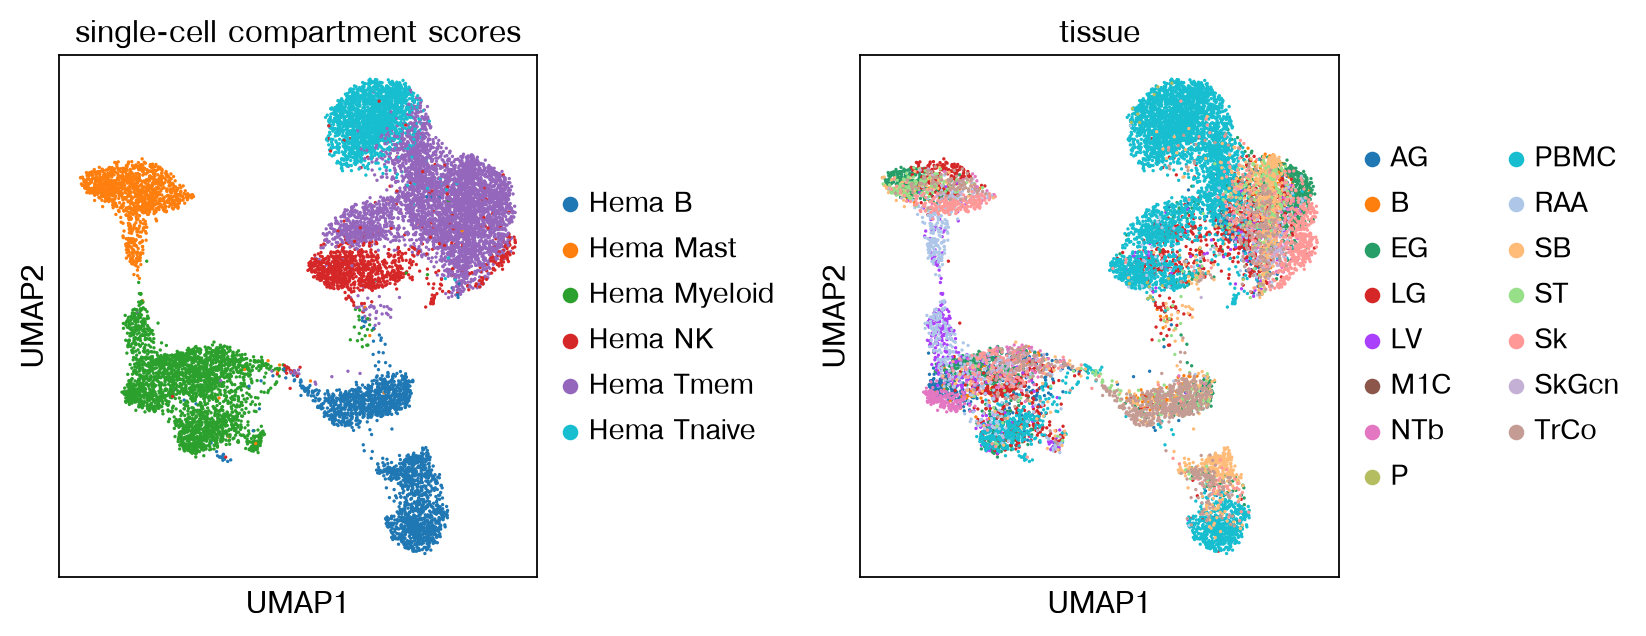

15-NN accuracy of the major type from 30 PCs: 0.967 ± 0.004 (largest class: 0.330)


In [17]:
import scanpy as sc
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

# z-score each bin in float64 (bins with CpG and a score that varies between cells)
X = np.asarray(sc_comp.X, dtype=np.float64)
mu, sd = X.mean(axis=0), X.std(axis=0)
use = (sc_comp.var['cpg_ratio'].to_numpy() > 0) & (sd > 1e-6 * np.abs(mu))
emb = sc_comp[:, use].copy()
emb.X = np.clip((X[:, use] - mu[use]) / sd[use], -10, 10).astype(np.float32)
emb.obs['major type'] = emb.obs['majortype'].map(L1_annot)
emb.obs['Tissue'] = adata.obs.loc[emb.obs_names, 'Tissue'].to_numpy()
sc.tl.pca(emb, n_comps=30)
sc.pp.neighbors(emb, n_neighbors=15)
sc.tl.umap(emb, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
sc.pl.umap(emb, color='major type', palette={L1_annot[c]: L1_color[c] for c in TYPES},
           ax=axes[0], show=False, title='single-cell compartment scores')
sc.pl.umap(emb, color='Tissue', ax=axes[1], show=False, title='tissue', palette=sc.pl.palettes.default_20)
plt.tight_layout(); plt.show()

acc = cross_val_score(KNeighborsClassifier(15), emb.obsm['X_pca'], emb.obs['major type'],
                      cv=StratifiedKFold(5, shuffle=True, random_state=0))
print(f'15-NN accuracy of the major type from 30 PCs: {acc.mean():.3f} ± {acc.std():.3f} '
      f'(largest class: {emb.obs["major type"].value_counts(normalize=True).iloc[0]:.3f})')

Single-cell compartment scores alone separate the six types (15-NN accuracy
0.967 against 0.33 for always guessing the largest type). Mast and naive T
cells form their own groups; memory T and NK cells overlap most; B cells split
by origin, blood (PBMC) apart from solid tissues.

Do single cells support the differential calls? For the bins dcHiC calls A in
type X and B in type Y, the single-cell score of X cells should exceed that of
Y cells at the same bins. Each cell gets its mean score over those bins; the
AUC is the probability that a random X cell scores higher than a random Y
cell (0.5 = no difference). Comparing cells of different types at the same
bins matters: the scHiCluster score also follows the local CpG density, so
scores of different bins are not comparable.

In [18]:
from sklearn.metrics import roc_auc_score
sel_bins = binall.index[selb]
dkey = (binall.loc[sel_bins, 'chr'] + ':' + binall.loc[sel_bins, 'start'].astype(str)).to_numpy()
dcol = pd.Series(np.arange(sc_comp.n_vars),
                 index=(sc_comp.var['chrom'].astype(str) + ':' + sc_comp.var['start'].astype(str)).to_numpy()).loc[dkey].to_numpy()
Xs = np.asarray(sc_comp.X[:, dcol], dtype=np.float64)
rows = []
for x in TYPES:
    for y in TYPES:
        if x == y:
            continue
        b = ((dcomp.loc[sel_bins, x] > 0) & (dcomp.loc[sel_bins, y] < 0)).to_numpy()
        if b.sum() < 10:
            continue
        sx = Xs[(sc_comp.obs['majortype'] == x).to_numpy()][:, b].mean(1)
        sy = Xs[(sc_comp.obs['majortype'] == y).to_numpy()][:, b].mean(1)
        auc = roc_auc_score(np.r_[np.ones(len(sx)), np.zeros(len(sy))], np.r_[sx, sy])
        rows.append({'A in': L1_annot[x], 'B in': L1_annot[y], 'bins': int(b.sum()),
                     'median score, A type': np.median(sx), 'median score, B type': np.median(sy), 'AUC': auc})
pd.DataFrame(rows).round(4)

,A in,B in,bins,"median score, A type","median score, B type",AUC
0,Hema Tmem,Hema Myeloid,244,0.0093,0.0087,0.9958
1,Hema Tmem,Hema B,265,0.0090,0.0084,0.9894
2,Hema Tmem,Hema Tnaive,94,0.0094,0.0089,0.9238
3,Hema Tmem,Hema Mast,320,0.0093,0.0086,0.9993
4,Hema Tmem,Hema NK,73,0.0087,0.0085,0.7813
5,Hema Myeloid,Hema Tmem,440,0.0088,0.0081,0.9977
6,Hema Myeloid,Hema B,358,0.0087,0.0082,0.9799
7,Hema Myeloid,Hema Tnaive,441,0.0089,0.0082,0.9981
8,Hema Myeloid,Hema Mast,367,0.0088,0.0082,0.9951
9,Hema Myeloid,Hema NK,362,0.0087,0.0081,0.9842


For 26 of the 30 ordered pairs of types, cells of the type called A score
higher than cells of the type called B with AUC ≥ 0.95 (median 0.995), so the
pseudobulk calls are carried by the cells. The weakest pairs are lymphocytes
that share most of their compartments, with few differential bins between
them: memory T vs NK (AUC 0.78, 73 bins) and memory T vs naive T (0.92).

## Summary

| Step | epione |
|---|---|
| raw pseudobulk per type | `epi.single.hic.merge_cells` |
| CpG track | `epi.single.hic.cpg_ratio` |
| PC model on merged contacts (bin filter, O/E, correlation, PCA, PC choice, CpG sign) | `epi.single.hic.compartment_model` |
| scores of every type on that model, bedGraphs | `epi.single.hic.project_compartments`, `write_bedgraph` |
| saddle plot and strength | `epi.single.hic.compartment_saddle` |
| dcHiC differential compartments (`dchicf.r --pcatype analyze`) | `epi.bulk.hic.differential_compartments` / `dchic_analyze` |
| scHiCluster single-cell score (`hicluster compartment`) | `epi.single.hic.compartment_scores` |

Not covered here: HCEA's imputed-contact compartments (this tutorial uses raw
contacts only) and the correlation of differential compartments with DNA
methylation, which needs the methylation data.